# Etap 6 — Analiza danych z wykorzystaniem metod grupowania

**Cel:** zastosowanie algorytmów grupowania w analizie danych.
**Rezultat etapu:** praktyczne wykorzystanie algorytmów **K-means** i **grupowania hierarchicznego** oraz ocena uzyskanych wyników (**silhouette score**).

Grupowanie wykonujemy na dwóch poziomach — odpowiadających praktycznym zastosowaniom z wytycznych:
- **A. Analiza rynku — grupy miast** o podobnej dostępności mieszkaniowej (15 miast, wskaźniki z etapu 3),
- **B. Segmentacja ofert (klientów/produktów)** — naturalne typy mieszkań na rynku (~91 tys. ofert).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.utils import *  # ścieżki, wczytywanie danych, styl wykresów

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, r2_score, silhouette_samples, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.tree import DecisionTreeRegressor

## 6.1 K-means i grupowanie hierarchiczne — zasady działania

| | **K-means** | **Grupowanie hierarchiczne (aglomeracyjne)** |
|---|---|---|
| Idea | podział na **k** grup; każdy obiekt należy do grupy o najbliższym **centroidzie** | zaczynamy od pojedynczych obiektów i **łączymy** najbliższe grupy aż do jednej |
| Liczba grup | trzeba podać **k** z góry (dobór: metoda łokcia, silhouette) | wybierana **po fakcie** — przez „przecięcie” dendrogramu |
| Algorytm | 1) losowe centroidy, 2) przypisanie do najbliższego, 3) przeliczenie centroidów, 4) powtarzanie do zbieżności | macierz odległości + kryterium łączenia (Ward, pełne, średnie) |
| Wynik | etykiety + centroidy | **dendrogram** (pełna hierarchia) + etykiety |
| Złożoność | niska (~liniowa w n) → duże zbiory | wysoka (pamięć O(n²)) → małe/średnie zbiory lub próbka |
| Kształt grup | sferyczne, podobnej wielkości | zależny od metody łączenia (Ward ≈ zwarte, sferyczne) |
| Determinizm | zależy od losowej inicjalizacji (stąd `n_init`) | deterministyczne |

**Wspólne:** obie metody opierają się na **odległości euklidesowej**, więc wymagają **atrybutów numerycznych** w porównywalnej skali (normalizacja!).

**Silhouette score** — dla obiektu *i*: $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$, gdzie *a* — średnia odległość do obiektów własnej grupy, *b* — do najbliższej obcej grupy.
Zakres [−1, 1]: blisko 1 — dobrze dopasowany, ~0 — na granicy grup, < 0 — prawdopodobnie w złej grupie.
**Warunki zastosowania:** co najmniej 2 grupy i mniej grup niż obiektów, atrybuty numeryczne z sensowną miarą odległości;
miara faworyzuje grupy zwarte i wypukłe; dla dużych zbiorów liczymy ją na próbce (koszt O(n²)).

---
# A. Grupowanie miast według dostępności mieszkaniowej

### Wybór atrybutów numerycznych
Wybieramy wskaźniki opisujące dostępność z różnych stron (ceny, dochody, relacje), unikając atrybutów powielających tę samą informację.
Ponieważ wskaźniki mają różne jednostki (PLN, %, liczba pensji), stosujemy **standaryzację** (z-score).

In [2]:
cities = pd.read_csv(PROCESSED_DIR / "miasta_wskazniki.csv")
CITY_FEATURES = ["mediana_cena_m2", "median_salary_net_pln", "miesiace_pensji_50m2", "dochod_dyspozycyjny",
                 "rentownosc_brutto_proc", "czynsz_do_pensji_proc", "cost_of_living_index"]
Xc = StandardScaler().fit_transform(cities[CITY_FEATURES])
cities.set_index("miasto")[CITY_FEATURES].round(1)

,mediana_cena_m2,median_salary_net_pln,miesiace_pensji_50m2,dochod_dyspozycyjny,rentownosc_brutto_proc,czynsz_do_pensji_proc,cost_of_living_index
miasto,,,,,,,
Białystok,"9,000.00",4311,104.40,1638,5.80,50.10,73.00
Bydgoszcz,"7,559.60",4475,84.50,1630,7.10,49.70,76.00
Częstochowa,"6,313.30",3874,81.50,1482,7.40,50.20,63.00
Gdańsk,"13,166.60",5457,120.60,2635,5.90,59.30,89.00
Gdynia,"11,500.00",5239,109.80,2549,5.70,52.20,86.00
Katowice,"7,899.00",4693,84.20,2021,7.30,51.10,80.00
Kraków,"14,946.00",5566,134.30,2810,5.10,57.60,92.00
Łódź,"7,963.00",4420,90.10,1693,6.80,50.80,76.00
Lublin,"9,202.50",4365,105.40,1658,6.60,57.60,74.00


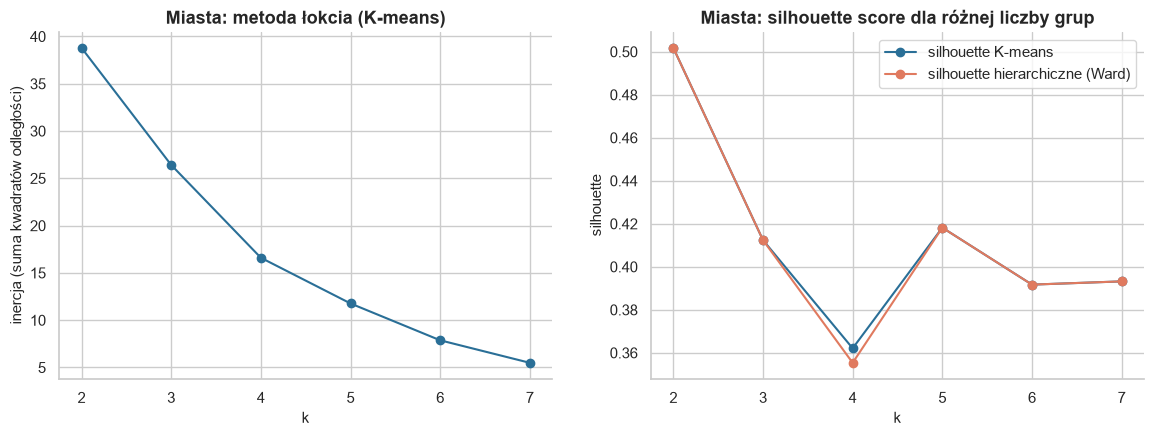

,inercja K-means,silhouette K-means,silhouette hierarchiczne (Ward)
k,,,
2,38.80,0.50,0.50
3,26.41,0.41,0.41
4,16.60,0.36,0.35
5,11.77,0.42,0.42
6,7.87,0.39,0.39
7,5.49,0.39,0.39


In [3]:
rows = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(Xc)
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(Xc)
    rows.append({"k": k, "inercja K-means": km.inertia_,
                 "silhouette K-means": silhouette_score(Xc, km.labels_),
                 "silhouette hierarchiczne (Ward)": silhouette_score(Xc, hc.labels_)})
city_k = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
city_k["inercja K-means"].plot(marker="o", ax=axes[0], color="#2a6f97")
axes[0].set_title("Miasta: metoda łokcia (K-means)")
axes[0].set_ylabel("inercja (suma kwadratów odległości)")
city_k[["silhouette K-means", "silhouette hierarchiczne (Ward)"]].plot(marker="o", ax=axes[1], color=["#2a6f97", "#e07a5f"])
axes[1].set_title("Miasta: silhouette score dla różnej liczby grup")
axes[1].set_ylabel("silhouette")
save_fig(fig, "06_miasta_dobor_k")
plt.show()
city_k.round(3)

**Dobór liczby grup:** silhouette jest najwyższy dla k = 2 (podział *metropolie vs ośrodki regionalne*) — to najbardziej „naturalny” podział,
ale zbyt ogólny dla celu analizy. Drugi wybór to k = 4–5; wybieramy **k = 4** — silhouette 0,36 (> 0,25 → struktura rozsądna), a grupy są
liczne (3–5 miast) i dobrze interpretowalne. Zgodnie z zasadą: o liczbie grup decyduje połączenie miary jakości i **użyteczności interpretacji**.

Maksimum silhouette: k = 2 (silhouette = 0.50)
  k = 2: {0: 'Białystok, Bydgoszcz, Częstochowa, Katowice, Łódź, Lublin, Radom, Rzeszów, Szczecin', 1: 'Gdańsk, Gdynia, Kraków, Poznań, Warszawa, Wrocław'}
  k = 4: {0: 'Gdynia, Poznań, Wrocław', 1: 'Bydgoszcz, Częstochowa, Katowice, Łódź, Radom', 2: 'Gdańsk, Kraków, Warszawa', 3: 'Białystok, Lublin, Rzeszów, Szczecin'}
Wybrana liczba grup do dalszej analizy: k = 4 (silhouette = 0.36)


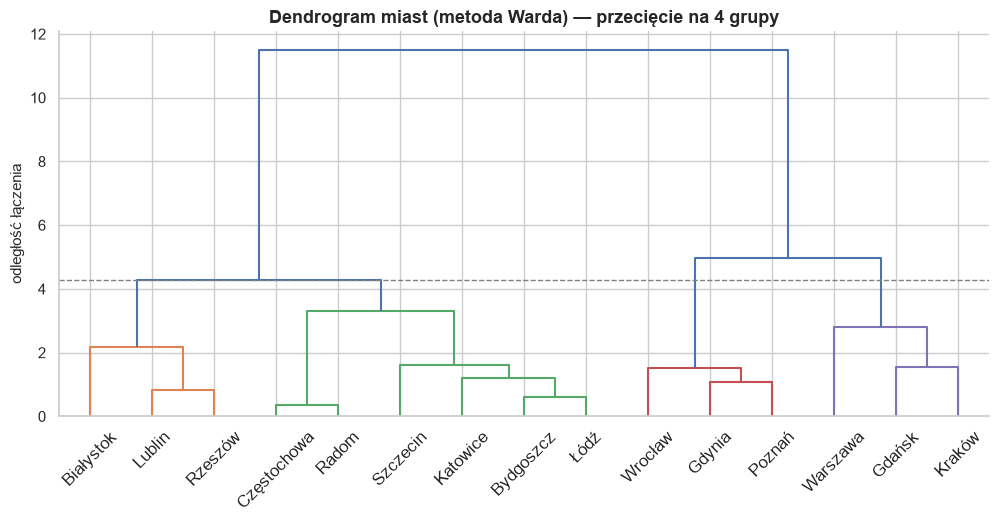

Zgodność K-means i hierarchicznego (ARI): 0.777


,miasto,klaster_kmeans,klaster_hier
4,Gdynia,0,2
9,Poznań,0,2
14,Wrocław,0,2
1,Bydgoszcz,1,1
2,Częstochowa,1,1
5,Katowice,1,1
7,Łódź,1,1
10,Radom,1,1
3,Gdańsk,2,3
6,Kraków,2,3


In [4]:
K_CITY_SIL = int(city_k["silhouette K-means"].idxmax())
print(f"Maksimum silhouette: k = {K_CITY_SIL} (silhouette = {city_k.loc[K_CITY_SIL, 'silhouette K-means']:.2f})")
for k in [2, 4]:
    lab = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit_predict(Xc)
    print(f"  k = {k}:", cities.groupby(lab)["miasto"].apply(lambda s: ", ".join(s)).to_dict())
K_CITY = 4
print(f"Wybrana liczba grup do dalszej analizy: k = {K_CITY} (silhouette = {city_k.loc[K_CITY, 'silhouette K-means']:.2f})")
km_city = KMeans(n_clusters=K_CITY, n_init=50, random_state=RANDOM_STATE).fit(Xc)
Z_city = linkage(Xc, method="ward")
hc_city = fcluster(Z_city, t=K_CITY, criterion="maxclust") - 1
cities["klaster_kmeans"] = km_city.labels_
cities["klaster_hier"] = hc_city

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z_city, labels=cities["miasto"].tolist(), ax=ax, leaf_rotation=45, color_threshold=Z_city[-(K_CITY - 1), 2])
ax.axhline(Z_city[-(K_CITY - 1), 2], color="gray", ls="--", lw=1)
ax.set_title(f"Dendrogram miast (metoda Warda) — przecięcie na {K_CITY} grupy")
ax.set_ylabel("odległość łączenia")
save_fig(fig, "06_miasta_dendrogram")
plt.show()

print("Zgodność K-means i hierarchicznego (ARI):", round(adjusted_rand_score(km_city.labels_, hc_city), 3))
cities[["miasto", "klaster_kmeans", "klaster_hier"]].sort_values("klaster_kmeans")

In [5]:
profile_city = cities.groupby("klaster_kmeans")[CITY_FEATURES + ["lata_wklad20_50proc_dysp"]].mean()
profile_city["miasta"] = cities.groupby("klaster_kmeans")["miasto"].apply(lambda s: ", ".join(s))
profile_city.round(1)

,mediana_cena_m2,median_salary_net_pln,miesiace_pensji_50m2,dochod_dyspozycyjny,rentownosc_brutto_proc,czynsz_do_pensji_proc,cost_of_living_index,lata_wklad20_50proc_dysp,miasta
klaster_kmeans,,,,,,,,,
0,"11,466.50","5,420.70",105.70,"2,703.70",5.90,51.50,87.70,7.10,"Gdynia, Poznań, Wrocław"
1,"7,205.90","4,267.20",84.30,"1,665.40",7.20,50.50,72.20,7.20,"Bydgoszcz, Częstochowa, Katowice, Łódź, Radom"
2,"14,936.00","5,638.70",132.20,"2,881.00",5.50,61.00,93.20,8.60,"Gdańsk, Kraków, Warszawa"
3,"9,246.60","4,406.20",105.00,"1,687.20",6.40,55.50,74.80,9.20,"Białystok, Lublin, Rzeszów, Szczecin"


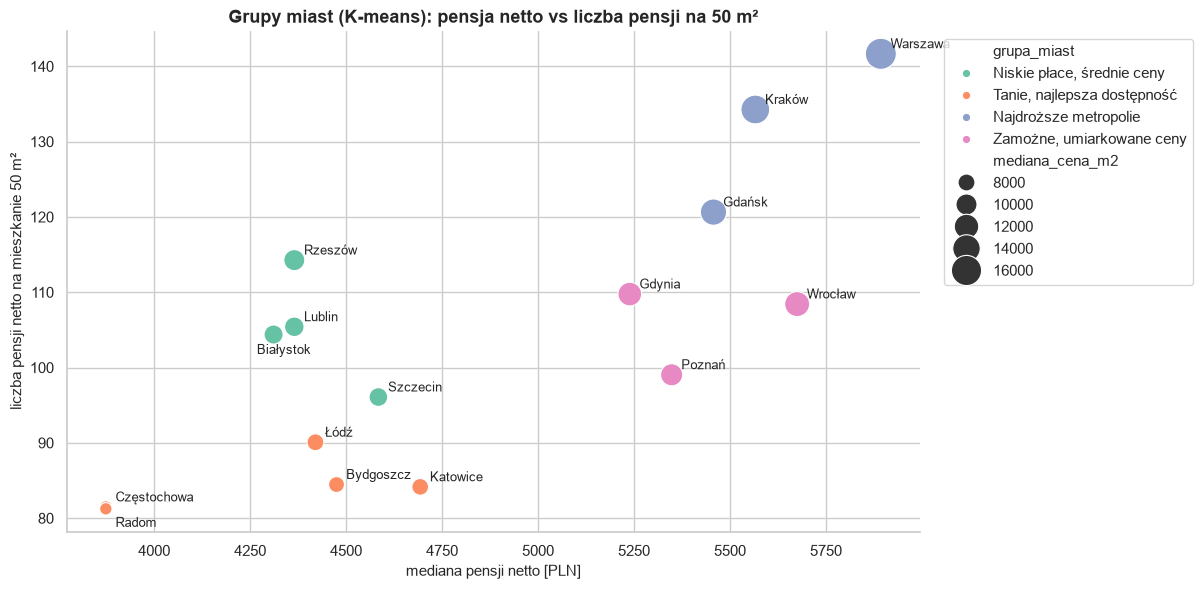

In [6]:
CITY_CLUSTER_NAMES = {"0": "Zamożne, umiarkowane ceny", "1": "Tanie, najlepsza dostępność", "2": "Najdroższe metropolie", "3": "Niskie płace, średnie ceny"}
cities["grupa_miast"] = cities["klaster_kmeans"].astype(str).map(CITY_CLUSTER_NAMES)

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.scatterplot(data=cities, x="median_salary_net_pln", y="miesiace_pensji_50m2", hue="grupa_miast",
                size="mediana_cena_m2", sizes=(80, 500), ax=ax, palette="Set2", legend="brief")
offsets = {"Radom": (7, -13), "Białystok": (-12, -14)}  # rozsunięcie nakładających się etykiet
for _, r in cities.iterrows():
    ax.annotate(r["miasto"], (r["median_salary_net_pln"], r["miesiace_pensji_50m2"]), xytext=offsets.get(r["miasto"], (7, 4)),
                textcoords="offset points", fontsize=9)
ax.set_title("Grupy miast (K-means): pensja netto vs liczba pensji na 50 m²")
ax.set_xlabel("mediana pensji netto [PLN]")
ax.set_ylabel("liczba pensji netto na mieszkanie 50 m²")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title=None)
save_fig(fig, "06_miasta_klastry")
plt.show()

---
# B. Segmentacja ofert mieszkań

### Wybór atrybutów numerycznych
Grupujemy oferty według **cech mieszkania i lokalizacji**, bez ceny — chcemy odkryć naturalne *typy mieszkań*, a dopiero potem sprawdzić,
jak różnią się cenowo (dzięki temu numer grupy można później bez wycieku informacji użyć jako atrybutu modelu ceny).

Atrybuty: `squareMeters`, `rooms`, `buildYear`, `floorCount`, `centreDistance`, `poiCount`, `amenities_count` — normalizowane **Min-Max** (jak w etapie 3).
Dla `poiCount` (silnie skośny) stosujemy wcześniej logarytm, by kilka ofert w ścisłym centrum nie „rozciągnęło” skali.

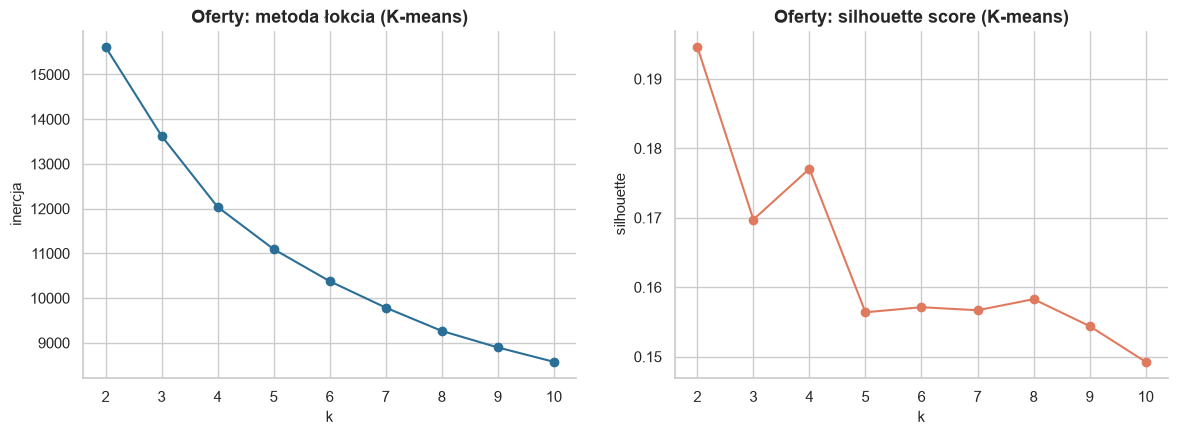

,inercja,silhouette (próbka 10 tys.)
k,,
2,"15,618.84",0.20
3,"13,627.17",0.17
4,"12,038.55",0.18
5,"11,094.61",0.16
6,"10,377.59",0.16
7,"9,786.61",0.16
8,"9,266.17",0.16
9,"8,897.18",0.15
10,"8,575.16",0.15


In [7]:
sales = pd.read_csv(PROCESSED_DIR / "oferty_sprzedaz_clean.csv")
OFFER_FEATURES = ["squareMeters", "rooms", "buildYear", "floorCount", "centreDistance", "poiCount", "amenities_count"]
F = sales[OFFER_FEATURES].copy()
F["poiCount"] = np.log1p(F["poiCount"])
Xo = MinMaxScaler().fit_transform(F)

rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(Xo), size=10000, replace=False)  # próbka do silhouette i grupowania hierarchicznego

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xo)
    rows.append({"k": k, "inercja": km.inertia_,
                 "silhouette (próbka 10 tys.)": silhouette_score(Xo[sample_idx], km.labels_[sample_idx])})
offer_k = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
offer_k["inercja"].plot(marker="o", ax=axes[0], color="#2a6f97")
axes[0].set_title("Oferty: metoda łokcia (K-means)")
axes[0].set_ylabel("inercja")
offer_k["silhouette (próbka 10 tys.)"].plot(marker="o", ax=axes[1], color="#e07a5f")
axes[1].set_title("Oferty: silhouette score (K-means)")
axes[1].set_ylabel("silhouette")
save_fig(fig, "06_oferty_dobor_k")
plt.show()
offer_k.round(3)

In [8]:
K_OFFER = int(offer_k.loc[3:8, "silhouette (próbka 10 tys.)"].idxmax())
print(f"Wybrana liczba segmentów (max silhouette dla k = 3…8): k = {K_OFFER}")
print("k = 2 pomijamy — dzieli rynek tylko na „stare/nowe”, co jest mało użyteczne biznesowo.")
km_offer = KMeans(n_clusters=K_OFFER, n_init=20, random_state=RANDOM_STATE).fit(Xo)
sales["klaster_kmeans"] = km_offer.labels_

Wybrana liczba segmentów (max silhouette dla k = 3…8): k = 4
k = 2 pomijamy — dzieli rynek tylko na „stare/nowe”, co jest mało użyteczne biznesowo.


### Grupowanie hierarchiczne (Ward) na próbce
Grupowanie hierarchiczne wymaga macierzy odległości (10 tys. obiektów → 50 mln par), dlatego wykonujemy je na losowej próbce 10 tys. ofert
i porównujemy z K-means na **tej samej próbce**.

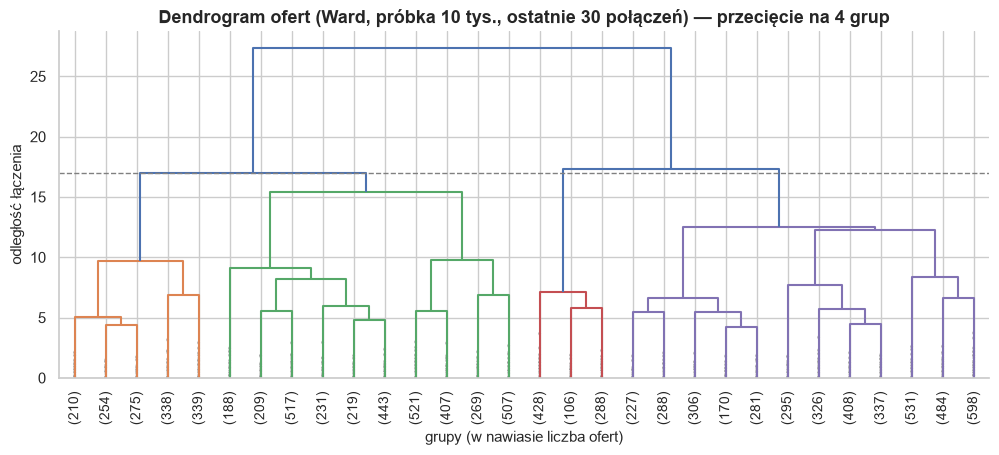

Zgodność podziałów K-means vs hierarchiczne (Adjusted Rand Index): 0.296


,silhouette
metoda,
K-means,0.18
hierarchiczne (Ward),0.13


In [9]:
Xs = Xo[sample_idx]
Z_off = linkage(Xs, method="ward")
hc_labels = fcluster(Z_off, t=K_OFFER, criterion="maxclust") - 1
km_labels_s = km_offer.labels_[sample_idx]

fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(Z_off, truncate_mode="lastp", p=30, ax=ax, leaf_rotation=90, show_contracted=True,
           color_threshold=Z_off[-(K_OFFER - 1), 2])
ax.axhline(Z_off[-(K_OFFER - 1), 2], color="gray", ls="--", lw=1)
ax.set_title(f"Dendrogram ofert (Ward, próbka 10 tys., ostatnie 30 połączeń) — przecięcie na {K_OFFER} grup")
ax.set_xlabel("grupy (w nawiasie liczba ofert)")
ax.set_ylabel("odległość łączenia")
save_fig(fig, "06_oferty_dendrogram")
plt.show()

# dopasowanie numeracji grup hierarchicznych do K-means 1:1 (algorytm węgierski) — tylko dla czytelności porównania
from scipy.optimize import linear_sum_assignment
ct = pd.crosstab(hc_labels, km_labels_s)
rows_i, cols_i = linear_sum_assignment(-ct.values)
mapping = dict(zip(ct.index[rows_i], ct.columns[cols_i]))
hc_aligned = pd.Series(hc_labels).map(mapping).values

compare_offer = pd.DataFrame([
    {"metoda": "K-means", "silhouette": silhouette_score(Xs, km_labels_s)},
    {"metoda": "hierarchiczne (Ward)", "silhouette": silhouette_score(Xs, hc_labels)},
]).set_index("metoda")
ari = adjusted_rand_score(km_labels_s, hc_labels)
print(f"Zgodność podziałów K-means vs hierarchiczne (Adjusted Rand Index): {ari:.3f}")
compare_offer.round(3)

In [10]:
pd.crosstab(pd.Series(km_labels_s, name="K-means"), pd.Series(hc_aligned, name="hierarchiczne (dopasowane)"),
            margins=True, margins_name="suma")

hierarchiczne (dopasowane),0,1,2,3,suma
K-means,,,,,
0,2631,420,25,78,3154
1,133,384,775,15,1307
2,951,17,2121,133,3222
3,536,1,590,1190,2317
suma,4251,822,3511,1416,10000


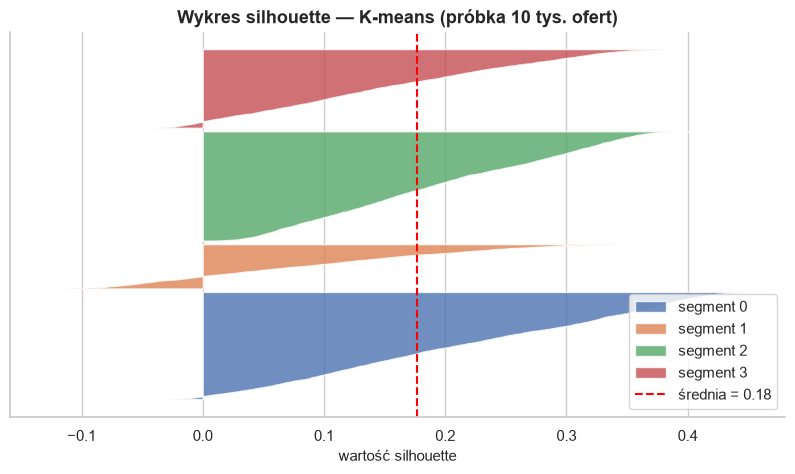

In [11]:
sil = silhouette_samples(Xs, km_labels_s)
fig, ax = plt.subplots(figsize=(10, 5))
y0 = 0
for c in range(K_OFFER):
    vals = np.sort(sil[km_labels_s == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, alpha=0.8, label=f"segment {c}")
    y0 += len(vals) + 100
ax.axvline(sil.mean(), color="red", ls="--", label=f"średnia = {sil.mean():.2f}")
ax.set_title("Wykres silhouette — K-means (próbka 10 tys. ofert)")
ax.set_xlabel("wartość silhouette")
ax.set_yticks([])
ax.legend(loc="lower right")
save_fig(fig, "06_oferty_silhouette")
plt.show()

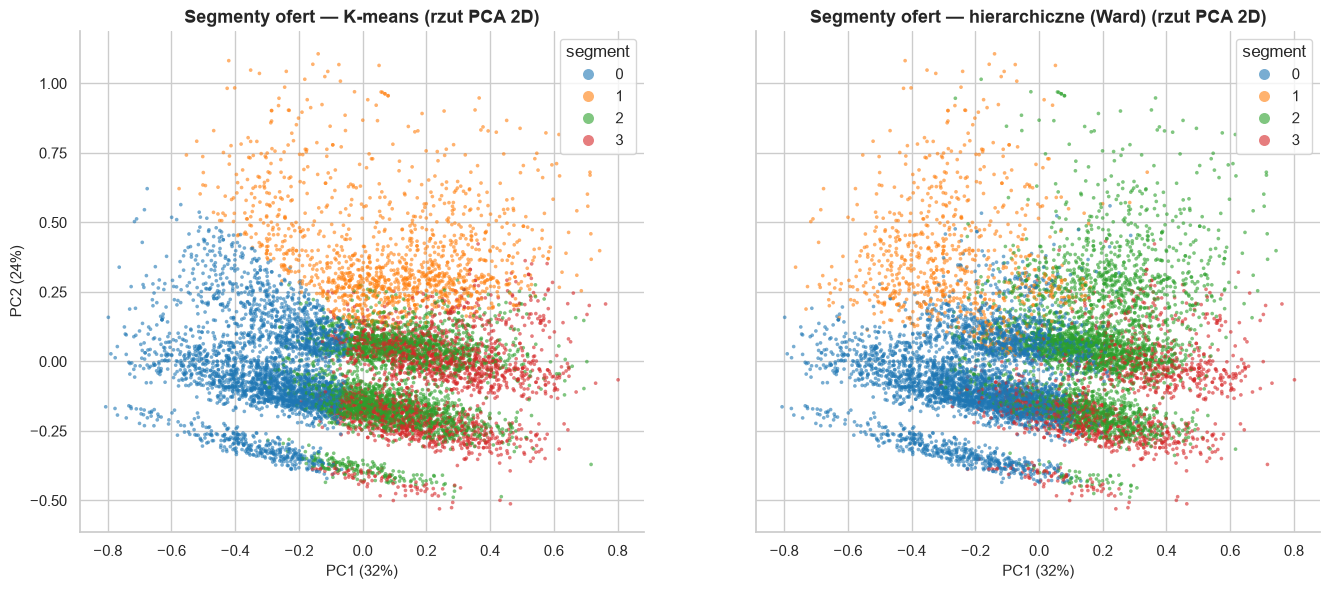

In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xo)
P = pca.transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True, sharey=True)
for ax, labels, title in [(axes[0], km_labels_s, "K-means"), (axes[1], hc_aligned, "hierarchiczne (Ward)")]:
    sc = sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=labels.astype(str), s=7, alpha=0.6, linewidth=0, ax=ax,
                         palette="tab10", hue_order=[str(i) for i in range(K_OFFER)])
    ax.set_title(f"Segmenty ofert — {title} (rzut PCA 2D)")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    ax.legend(title="segment", markerscale=3)
save_fig(fig, "06_oferty_klastry_pca")
plt.show()

### Profile segmentów
Interpretujemy grupy na podstawie median atrybutów w **oryginalnych jednostkach** oraz sprawdzamy, jak segmenty różnią się ceną (która *nie* brała udziału w grupowaniu).

In [13]:
profile_offer = sales.groupby("klaster_kmeans").agg(
    liczba_ofert=("id", "size"), metraz=("squareMeters", "median"), pokoje=("rooms", "median"),
    rok_budowy=("buildYear", "median"), pietra_budynku=("floorCount", "median"),
    odl_centrum_km=("centreDistance", "median"), poi_500m=("poiCount", "median"),
    udogodnienia=("amenities_count", "mean"), cena_m2=("price_per_m2", "median"),
    indeks_ceny_miasto=("price_index_city", "median"), cena=("price", "median"))
profile_offer["udział [%]"] = profile_offer["liczba_ofert"] / len(sales) * 100
profile_offer.round(1)

,liczba_ofert,metraz,pokoje,rok_budowy,pietra_budynku,odl_centrum_km,poi_500m,udogodnienia,cena_m2,indeks_ceny_miasto,cena,udział [%]
klaster_kmeans,,,,,,,,,,,,
0,28366,47.00,2.00,"1,963.00",4.00,2.50,22.00,1.10,"12,632.10",101.20,"576,000.00",31.10
1,12065,88.00,4.00,"1,995.00",4.00,4.00,15.00,2.00,"12,300.00",92.80,"1,072,500.00",13.20
2,29980,50.00,2.00,"2,000.00",7.00,4.50,15.00,2.80,"14,225.00",103.80,"690,000.00",32.80
3,20881,54.40,3.00,"2,012.00",4.00,6.50,4.00,1.70,"12,892.90",95.80,"680,000.00",22.90


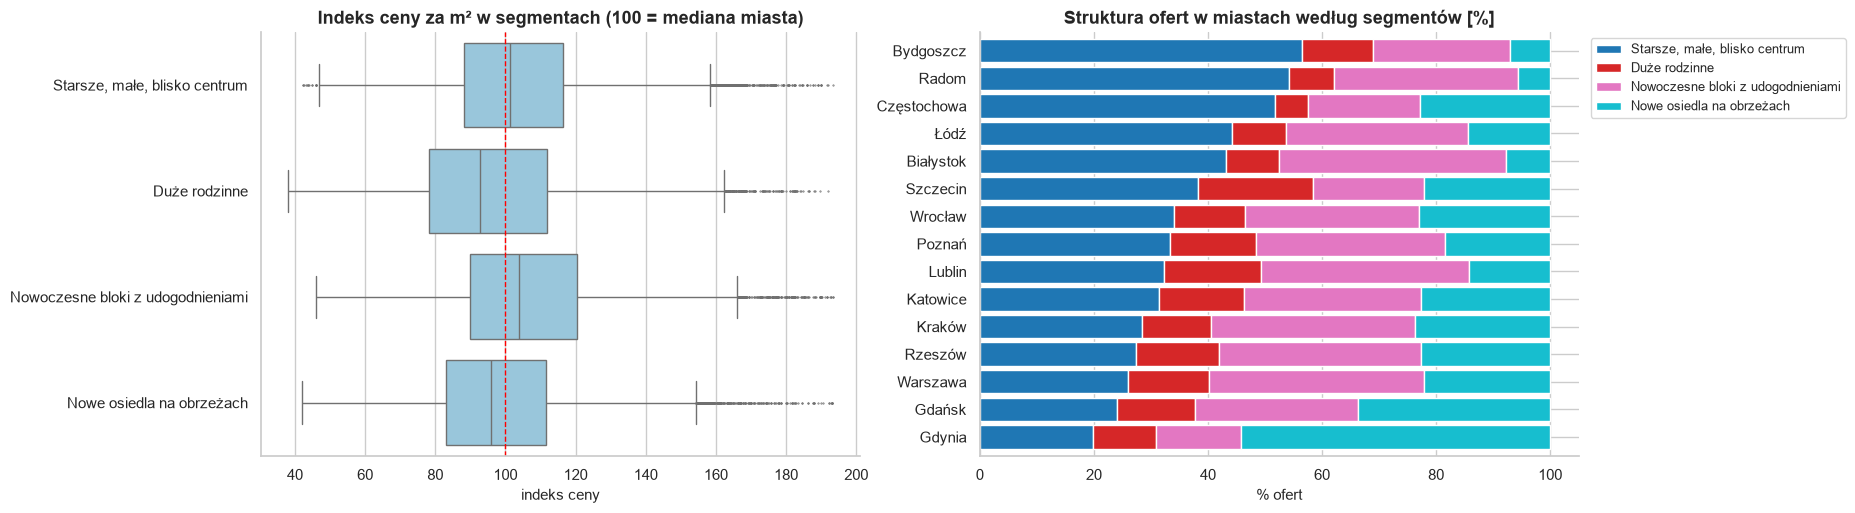

In [14]:
OFFER_CLUSTER_NAMES = {"0": "Starsze, małe, blisko centrum", "1": "Duże rodzinne", "2": "Nowoczesne bloki z udogodnieniami", "3": "Nowe osiedla na obrzeżach"}
sales["segment_rynku"] = sales["klaster_kmeans"].astype(str).map(OFFER_CLUSTER_NAMES)
seg_order = [OFFER_CLUSTER_NAMES.get(str(i), str(i)) for i in range(K_OFFER)]

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
sns.boxplot(data=sales, y="segment_rynku", x="price_index_city", order=seg_order, ax=axes[0], color="#8ecae6", fliersize=0.5)
axes[0].axvline(100, color="red", ls="--", lw=1)
axes[0].set_title("Indeks ceny za m² w segmentach (100 = mediana miasta)")
axes[0].set_ylabel("")
axes[0].set_xlabel("indeks ceny")
share = pd.crosstab(sales["city_label"], sales["segment_rynku"], normalize="index")[seg_order] * 100
share = share.loc[share[seg_order[0]].sort_values().index]
share.plot(kind="barh", stacked=True, ax=axes[1], colormap="tab10", width=0.85)
axes[1].set_title("Struktura ofert w miastach według segmentów [%]")
axes[1].set_xlabel("% ofert")
axes[1].set_ylabel("")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
save_fig(fig, "06_segmenty_ceny_miasta")
plt.show()

---
## 6.2 Łączenie metod nienadzorowanych i nadzorowanych

Sprawdzamy, czy **numer segmentu z K-means** (metoda nienadzorowana) poprawia **drzewo decyzyjne** przewidujące cenę za m² (metoda nadzorowana, etap 5).
Porównujemy drzewa płytkie (głęb. 3 i 6 — czytelne reguły) i głębokie (głęb. 15 — jak w etapie 5).

In [15]:
cities_feat = cities.set_index("city_key")[["median_salary_net_pln", "cost_of_living_index", "population_approx"]]
data = sales.join(cities_feat, on="city")
base_cols = ["squareMeters", "rooms", "floor", "floorCount", "buildYear", "centreDistance", "poiCount",
             "schoolDistance", "clinicDistance", "postOfficeDistance", "kindergartenDistance", "restaurantDistance",
             "collegeDistance", "pharmacyDistance", "hasParkingSpace", "hasBalcony", "hasElevator", "hasSecurity",
             "hasStorageRoom", "median_salary_net_pln", "cost_of_living_index", "population_approx"]
X_base = data[base_cols]
X_plus = pd.concat([X_base, pd.get_dummies(data["klaster_kmeans"], prefix="segment", dtype=int)], axis=1)
y = data["price_per_m2"]
idx_train, idx_test = train_test_split(data.index, test_size=0.2, random_state=RANDOM_STATE, stratify=data["city"])

rows = []
for depth in [3, 6, 15]:
    for name, Xm in [("bez segmentu", X_base), ("+ segment K-means", X_plus)]:
        m = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=5, random_state=RANDOM_STATE)
        m.fit(Xm.loc[idx_train], y.loc[idx_train])
        rows.append({"głębokość drzewa": depth, "atrybuty": name, "R² (test)": r2_score(y.loc[idx_test], m.predict(Xm.loc[idx_test]))})
combined = pd.DataFrame(rows).pivot(index="głębokość drzewa", columns="atrybuty", values="R² (test)")
combined["zmiana R²"] = combined["+ segment K-means"] - combined["bez segmentu"]
combined.round(4)

atrybuty,+ segment K-means,bez segmentu,zmiana R²
głębokość drzewa,,,
3,0.59,0.59,0.00
6,0.70,0.70,0.00
15,0.79,0.79,-0.00


## 6.3 Zapis wyników

In [16]:
cities.to_csv(PROCESSED_DIR / "miasta_klastry.csv", index=False)

P_all = pca.transform(Xo)
sales_out = sales[["id", "city", "city_label", "price", "price_per_m2", "price_index_city", "squareMeters", "rooms",
                   "buildYear", "centreDistance", "poiCount", "segment_cenowy", "strefa", "epoka_budowy",
                   "klaster_kmeans", "segment_rynku"]].copy()
sales_out["PC1"], sales_out["PC2"] = P_all[:, 0].round(4), P_all[:, 1].round(4)
sales_out.to_csv(PROCESSED_DIR / "oferty_klastry.csv", index=False)

clustering_results = pd.DataFrame([
    {"poziom": "miasta (15)", "metoda": "K-means", "k": K_CITY, "silhouette": city_k.loc[K_CITY, "silhouette K-means"],
     "ARI vs druga metoda": adjusted_rand_score(km_city.labels_, hc_city)},
    {"poziom": "miasta (15)", "metoda": "hierarchiczne (Ward)", "k": K_CITY,
     "silhouette": silhouette_score(Xc, hc_city), "ARI vs druga metoda": adjusted_rand_score(km_city.labels_, hc_city)},
    {"poziom": "oferty (próbka 10 tys.)", "metoda": "K-means", "k": K_OFFER,
     "silhouette": compare_offer.loc["K-means", "silhouette"], "ARI vs druga metoda": ari},
    {"poziom": "oferty (próbka 10 tys.)", "metoda": "hierarchiczne (Ward)", "k": K_OFFER,
     "silhouette": compare_offer.loc["hierarchiczne (Ward)", "silhouette"], "ARI vs druga metoda": ari},
])
clustering_results.to_csv(PROCESSED_DIR / "wyniki_grupowania.csv", index=False)
clustering_results.round(3)

,poziom,metoda,k,silhouette,ARI vs druga metoda
0,miasta (15),K-means,4,0.36,0.78
1,miasta (15),hierarchiczne (Ward),4,0.35,0.78
2,oferty (próbka 10 tys.),K-means,4,0.18,0.30
3,oferty (próbka 10 tys.),hierarchiczne (Ward),4,0.13,0.30


## 6.4 Ocena efektywności i porównanie metod

### A. Grupy miast (k = 4, silhouette 0,36; K-means i Ward zgodne w 14 z 15 miast, ARI = 0,78)

| Grupa | Miasta | Charakterystyka |
|---|---|---|
| **Najdroższe metropolie** | Warszawa, Kraków, Gdańsk | najwyższe ceny (~14,9 tys. PLN/m²) i płace, ale **najgorsza dostępność** (~132 pensje na 50 m²), najniższa rentowność najmu (5,5%) |
| **Zamożne, umiarkowane ceny** | Wrocław, Poznań, Gdynia | wysokie płace przy wyraźnie niższych cenach → **najkrótszy czas zbierania na wkład własny** (~7,1 roku) |
| **Tanie, najlepsza dostępność** | Łódź, Katowice, Bydgoszcz, Częstochowa, Radom | najniższe ceny (~7,2 tys. PLN/m²), ~84 pensje na 50 m², **najwyższa rentowność najmu** (7,2%) — rynki dla inwestorów |
| **Niskie płace, średnie ceny** | Białystok, Lublin, Rzeszów, Szczecin | ceny jak na ośrodki regionalne wysokie względem niskich płac → **najdłuższe zbieranie na wkład** z dochodu dyspozycyjnego (~9,2 roku) |

Silhouette jest najwyższy dla k = 2 (0,50: metropolie vs reszta), ale podział na 4 grupy ujawnia ważną różnicę: miasta *tanie* nie są tym samym co *dostępne* —
ośrodki ściany wschodniej i Szczecin mają średnie ceny, ale niskie płace, więc względna dostępność jest tam gorsza niż we Wrocławiu czy Poznaniu.
Jedyna różnica między metodami: Szczecin (Ward łączy go z grupą „tanich”) — to miasto graniczne między grupami.

### B. Segmenty ofert (k = 4)

| Segment | Udział | Profil | Cena względem miasta |
|---|---|---|---|
| **Starsze, małe, blisko centrum** | 31% | ~47 m², 1963 r., 2,5 km od centrum, dużo usług w okolicy | ≈ mediana (101) |
| **Duże rodzinne** | 13% | ~88 m², 4 pokoje | **najtańsze za m²** (93) — efekt skali |
| **Nowoczesne bloki z udogodnieniami** | 33% | ~2000 r., 7 pięter, winda/parking/ochrona | **najdroższe** (104) |
| **Nowe osiedla na obrzeżach** | 23% | ~2012 r., 6,5 km od centrum, mało usług | poniżej mediany (96) — nowość nie rekompensuje lokalizacji |

- Struktura rynku różni się między miastami: w Bydgoszczy, Radomiu i Częstochowie ponad połowa ofert to stare, małe mieszkania; w Gdyni i Gdańsku dominują nowe osiedla na obrzeżach.
- **Ocena jakości:** silhouette jest niski (0,18 dla K-means, 0,13 dla Warda) — rynek mieszkań jest **ciągły**, a segmenty płynnie przechodzą jeden w drugi (brak wyraźnych przerw między grupami).
  Segmenty są jednak interpretowalne i różnią się cenowo, więc są użyteczne opisowo. K-means daje lepszy silhouette niż Ward, a zgodność podziałów jest umiarkowana (ARI = 0,30) —
  przy słabej strukturze danych różne algorytmy „tną” rynek w różnych miejscach.

### Porównanie metod — podobieństwa i różnice w praktyce
- **Podobieństwa:** obie metody wymagają normalizacji i wyboru liczby grup; na danych z wyraźną strukturą (miasta) dają niemal identyczne wyniki.
- **Różnice:** grupowanie hierarchiczne daje dendrogram (widać, które miasta są najbliżej siebie i przy jakim poziomie łączą się grupy), ale nie skaluje się na 91 tys. ofert (wymagało próbki);
  K-means działa na pełnym zbiorze w sekundy i daje centroidy, ale wymaga podania k z góry i zakłada grupy sferyczne.

### Łączenie metod
Dodanie numeru segmentu do drzewa decyzyjnego **nie poprawiło** wyniku (zmiana R² ≈ 0). Segment jest funkcją atrybutów, które drzewo już ma (metraż, rok, odległość…),
więc nie wnosi nowej informacji — drzewo samo potrafi wyznaczyć takie podziały. Łączenie metod daje korzyść, gdy grupowanie wykorzystuje **inne dane** niż model
lub gdy model jest bardzo prosty (np. liniowy); w naszym przypadku wartością segmentacji jest przede wszystkim **interpretacja rynku**.